In [1]:
import sys
import os


import numpy as np
import matplotlib.pyplot as plt
import scipy
import astropy.units as u
from astropy.time import Time
import astropy.cosmology as acosmo
from astropy.coordinates import SkyCoord
from astropy.table import QTable
import astropy_healpix as ah
import pandas as pd
from scipy.interpolate import interp1d
import ligo.skymap.plot #used implicitely
import mhealpy as mhp
import healpy as hp
import copy
from firesong.Firesong import firesong_simulation
from firesong.FluxPDF import flux_pdf
from scipy.special import factorial


sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube')
from transient_rates import R_CC, R_TDE, R_sGRB_gaus, plot_rates
from params import p_cosmology, p
from ic_visualization_clean import read_map, plot_map, evaluate_map, get_map_area, \
    get_moc_map_metadata, get_max_ra_dec_from_map, is_source_in_contour_area
from Rubicube import effective_area, signal_energy_pdf





/Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [2]:
time = (40 * u.d).to(u.s).value
sim_values = firesong_simulation('./', density=1e-6, Evolution='CC2015SNR', zmax=10.0,
                    fluxnorm=1.44e-8, index=2.52, LF='SC', Transient=True, timescale=time,
                    filename=None)

##############################################################################
##### FIRESONG initializing  - Calculating Neutrino CDFs #####
Standard candle sources+
Transient Sources, time scale = 3456000.0s
Source evolution assumed: CC2015SNR
Local density of neutrino sources: 1e-06/Mpc^3
Total number of neutrinos sources in the Universe: 2423376
Redshift range: 0 - 10.0
Standard Candle Luminosity: 1.7899e+51 erg/yr
##### FIRESONG initialization done #####

Actual diffuse flux simulated :
E^2 dNdE = 1.8421343538019072e-08 (E/100 TeV)^(-0.52) [GeV/cm^2.s.sr]


In [3]:
sim_values

{'header': {'LF': 'SC',
  'Transient': True,
  'timescale': np.float64(3456000.0),
  'fluxnorm': 1.44e-08,
  'delta_gamma': -0.52,
  'luminosity': np.float64(1.7898734716603088e+51)},
 'total_flux': np.float64(1.8421343538019072e-08),
 'sources': {'dec': array([ -8.45898759, -17.49632525, -60.868772  , ...,  59.76467615,
           7.68974386,  16.11404546], shape=(2423376,)),
  'ra': array([189.79466323, 164.27333484, 273.98595301, ..., 293.12576654,
          28.80022778, 276.66506839], shape=(2423376,)),
  'flux': array([5.42339115e-15, 3.39460614e-15, 4.56733450e-15, ...,
         2.03406462e-14, 2.98737006e-15, 3.30896660e-15], shape=(2423376,)),
  'z': array([3.41403887, 3.89281893, 3.58262452, ..., 2.3468385 , 4.03423439,
         3.92070647], shape=(2423376,))}}

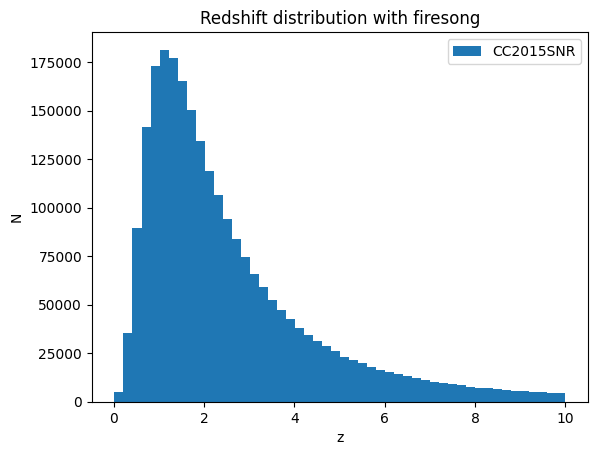

In [4]:
plt.hist(sim_values['sources']['z'], bins=50, label='CC2015SNR')
plt.xlabel('z')
plt.ylabel('N')
plt.title('Redshift distribution with firesong')
plt.legend()
plt.show()

In [5]:
def create_gaussian_healpix_map(ra, dec, nside, sigma_deg):
    """
    Generates a HEALPix map with a Gaussian profile centered at a given RA/DEC.
    
    Parameters:
        ra (float): Right Ascension in degrees [0, 360]
        dec (float): Declination in degrees [-90, 90]
        nside (int): HEALPix resolution parameter (must be a power of 2)
        sigma_deg (float): Standard deviation (width) of the Gaussian in degrees
        
    Returns:
        np.ndarray: The HEALPix map array
    """
    # 1. Calculate total number of pixels
    npix = hp.nside2npix(nside)
    
    # 2. Convert target RA/DEC to HEALPix spherical coordinates (theta, phi)
    # Theta is colatitude (0 at North Pole, pi at South Pole)
    # Phi is longitude (0 to 2*pi)
    target_theta = np.radians(90.0 - dec)
    target_phi = np.radians(ra)
    
    # 3. Get spherical coordinates for the center of every pixel in the map
    pixel_indices = np.arange(npix)
    pixel_thetas, pixel_phis = hp.pix2ang(nside, pixel_indices)
    
    # 4. Calculate angular distance (angular separation) between the target 
    # center and every pixel on the sphere
    angular_distances = hp.rotator.angdist(
        [target_theta, target_phi], 
        [pixel_thetas, pixel_phis]
    )
    
    # 5. Convert sigma from degrees to radians
    sigma_rad = np.radians(sigma_deg)
    
    # 6. Compute the Gaussian profile 
    # Amplitude is normalized to 1 at the peak
    hp_map = np.exp(-0.5 * (angular_distances / sigma_rad)**2)

    #create skymap object
    gaussian_map = hp_map / np.sum(hp_map)
    pixel_area = ah.nside_to_pixel_area(nside)
    prob_density = gaussian_map / pixel_area
    m = mhp.HealpixMap(data=gaussian_map, nside=nside)
    
    skymap = QTable({
            'ABSPROB': gaussian_map,
            'PROBDENSITY': prob_density,
            'UNIQ': m.uniq
            
        })
    alert = {
        'skymap': skymap,
        'moc': m
    }
    
    return alert

def generate_random_alerts(N_alerts, nside=512, sigma=0.5):
    '''
    Generates N_alerts uniformly distributed in the sky'''

    #generate N_alerts random alerts:
    alerts = []
    for i in range(N_alerts):
        ra_alert = np.random.uniform(0, 360)
        dec_alert = np.random.uniform(-90, 90)
        sigma = np.random.uniform(0.3, 0.6)
        alert = create_gaussian_healpix_map(ra_alert, dec_alert, nside, sigma)
        alerts.append(alert)
        
    return alerts

In [6]:
def get_selection_zoom(ra, dec, ra_zoom, dec_zoom, area_90=3, size=5):
    '''
    Does a conesearch of sources within a certain radius of ra_zoom and dec_zoom, and returns a boolean array of the same dimensions as ra and dec.
    Radius is compites as size * np.sqrt(Area_90). 
    '''
    catalog = SkyCoord(ra=ra * u.deg, dec=dec * u.deg)
    center_point = SkyCoord(ra=ra_zoom * u.deg, dec=dec_zoom * u.deg)
    radius = size * np.sqrt(area_90) 
    
    separation = center_point.separation(catalog)
    selection_zoom = separation < radius

    return selection_zoom


def plot_population(population, alerts, r=1, p=0.9, plot_specific_alert=None):

    '''
    population: dict. Transient poopulation
    alerts: list of list. Randmom;y generated alerts. Each element is [QTable, HealpixMap]
    '''
    ra = population['ra']
    dec= population['dec']

    

    
    #get total map for plotting
    if isinstance(plot_specific_alert, int):
         original_alert = alerts.pop(plot_specific_alert)
    else:
        original_alert = alerts.pop() 
    sel_alert = copy.deepcopy(original_alert)
    total_map = copy.deepcopy(sel_alert)['moc']
    ra_zoom, dec_zoom = get_max_ra_dec_from_map(total_map) #we zoom in on the first generated alert

    
    
    
    
    #plotting
    fig = plt.figure(figsize=(6, 6), dpi=100)
    ax = plt.axes(
        [0.05, 0.05, 0.8, 0.9],
        projection='astro degrees mollweide',
        center=SkyCoord(0 * u.rad, 0 * u.rad, frame='icrs'))
    
    ax_inset = plt.axes(
            [1.03, 0.3, 0.42, 0.42],
            projection='astro degrees zoom',
            center=SkyCoord(ra_zoom * u.deg, dec_zoom * u.deg, frame='icrs'),
            radius=r * u.deg)
    for key in ['ra', 'dec']:
        ax_inset.coords[key].set_ticks_visible(False)


    
    

    
    ax.set_title(r'$N_{total} =$ ' + np.format_float_scientific(len(ra), 1) + f' time = {population['time_window'].to(u.d)}  z_max={population["z_max"]}')

    ax_inset.set_xlabel("")
    ax_inset.set_ylabel("")
    ax.grid()
    ax.locator_params(nbins=10) #test!
    ax.mark_inset_axes(ax_inset)
    ax.connect_inset_axes(ax_inset, 'upper left')
    ax.connect_inset_axes(ax_inset, 'lower left')
    ax_inset.scalebar((0.1, 0.1), 1 * u.deg).label()
    ax_inset.compass(0.9, 0.1, 0.2)
    ax_inset.grid()
    
    
    ax_inset.set_title(fr'RA: {ra_zoom:.2f}$\degree$  DEC: {dec_zoom:.2f}$\degree$')


    
    #plot alerts
    img_inset = sel_alert['moc'].get_wcs_img(ax_inset)
    im = ax_inset.imshow(img_inset, cmap='Greens')
    c = plt.colorbar(im, label=r'Probability')
    
    for alert in alerts:
        total_map += alert['moc']
    img_inset = total_map.get_wcs_img(ax)
    im = ax.imshow(img_inset, cmap='Greens')

    

    #plot SN
    ax.plot(ra, dec, '.', c='orange', ms=0.01, transform=ax.get_transform('world'))

    
    #50 & 90% ontour
    skymap = copy.deepcopy(sel_alert)['skymap']
    skymap.sort("PROBDENSITY", reverse=True)
    sorted_metadata = get_moc_map_metadata(skymap)
    # prob = sorted_metadata['PIXELAREA'] * skymap["PROBDENSITY"]
    prob = skymap['ABSPROB']
    cumprob = np.cumsum(prob)
    # searchsorted gives the FIRST index where cumprob >= target.
    i_50 = cumprob.searchsorted(0.5)
    i_90 = cumprob.searchsorted(0.9)
    
    m_prob = mhp.HealpixMap(data=cumprob, uniq=skymap['UNIQ'], density=True)
    img = m_prob.get_wcs_img(ax_inset)#, coord = coord, rasterize = rasterize)
    im = ax_inset.contour(img, levels=[0.5, 0.9], colors=['black', 'black'], linestyles=['solid', 'dashed'])

    area_50 = sorted_metadata['PIXELAREA'][:i_50].sum().to(u.deg**2)
    area_90 = sorted_metadata['PIXELAREA'][:i_90].sum().to(u.deg**2)

    #plot inset sn

    selection_zoom = get_selection_zoom(ra, dec, ra_zoom, dec_zoom, area_90=area_90)
    ax_inset.plot(
        ra[selection_zoom],
        dec[selection_zoom],
        'o',
        c='orange', ms=1, transform=ax_inset.get_transform('world'))
    
    #we also colour the accepted pixels within a p_value
    ra_accepted, dec_accepted = is_source_in_contour_area(original_alert['skymap'], ra[selection_zoom], dec[selection_zoom], p=p)
    if len(ra_accepted) >0:
        ax_inset.plot(
            ra_accepted,
            dec_accepted,
            'o',
            c='cyan', ms=1, transform=ax_inset.get_transform('world'),
            label=f'{100 * p:.1f}%')
    

    

    print("Area 50%: ", area_50)
    print("Area 90%: ", area_90)

    #plot
    ax_inset.legend(framealpha=1)
    plt.show()

    return original_alert

In [7]:

time = (40 * u.d).to(u.s).value
z_max = 1
sim_values = firesong_simulation('./', density=1e-6, Evolution='CC2015SNR', zmax=10,
                    fluxnorm=1.44e-8, index=2.28, LF='SC', Transient=True, timescale=time,
                    filename=None)
boolean_array = sim_values['sources']['z'] < z_max


for key in sim_values['sources'].keys():
    sim_values['sources'][key] = sim_values['sources'][key][boolean_array]
alerts = generate_random_alerts(N_alerts=100, sigma=0.3)

##############################################################################
##### FIRESONG initializing  - Calculating Neutrino CDFs #####
Standard candle sources+
Transient Sources, time scale = 3456000.0s
Source evolution assumed: CC2015SNR
Local density of neutrino sources: 1e-06/Mpc^3
Total number of neutrinos sources in the Universe: 2423376
Redshift range: 0 - 10
Standard Candle Luminosity: 1.4948e+51 erg/yr
##### FIRESONG initialization done #####

Actual diffuse flux simulated :
E^2 dNdE = 1.902498114847112e-08 (E/100 TeV)^(-0.2799999999999998) [GeV/cm^2.s.sr]


Area 50%:  1.5212197319452405 deg2
Area 90%:  5.0882177240927 deg2


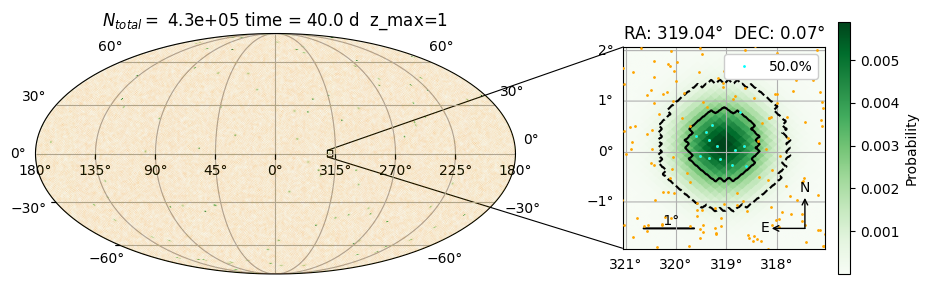

In [8]:
population = {
    'ra': sim_values['sources']['ra'],
    'dec': sim_values['sources']['dec'],
    'time_window': sim_values['header']['timescale'] * u.s,
    'z_max': z_max
}
sel_alert = plot_population(population, alerts, r=2, p=0.50) 

In [9]:
pop_pdf = flux_pdf(outputdir=None, density=1e-05, Evolution='CC2015SNR', Transient=True, 
    timescale=time, LF='LG')

##############################################################################
##### FIRESONG initializing  - Calculating Flux PDF#####
Lognormal distributed sources
Transient Sources, time scale = 3456000.0s
Source evolution assumed: CC2015SNR
Local density of neutrino sources: 1e-05/Mpc^3
Total number of neutrinos sources in the Universe: 24233763.701812953
Redshift range: 0 - 10.0
Standard Candle Luminosity: 1.4948e+50 erg/yr
##### FIRESONG initialization done #####



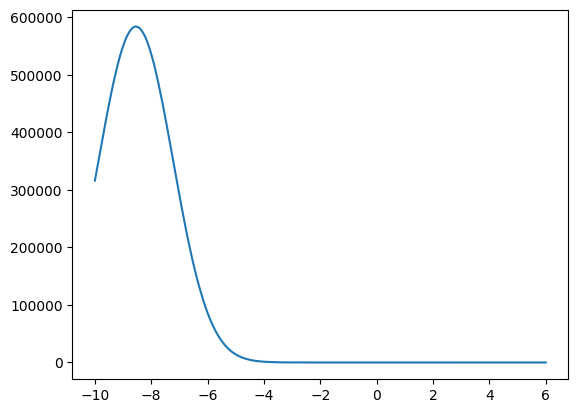

In [10]:
plt.plot(pop_pdf[0], pop_pdf[1])
plt.show()

In [11]:
# n_accepted_sources_90 = []
# n_accepted_sources_50 = []
# n_accepted_sources_99 = []
# for alert in alerts:
#     ra_accepted_50, _ = is_source_in_contour_area(alert['skymap'], population['ra'], population['dec'],
#                                                           p=0.5)
#     ra_accepted_90, _ = is_source_in_contour_area(alert['skymap'], population['ra'], population['dec'],
#                                                           p=0.9)
#     ra_accepted_99, _ = is_source_in_contour_area(alert['skymap'], population['ra'], population['dec'],
#                                                           p=0.99)
#     n_accepted_sources_50.append(len(ra_accepted_50))
#     n_accepted_sources_90.append(len(ra_accepted_90))
#     n_accepted_sources_99.append(len(ra_accepted_99))

In [12]:
# fig, ax = plt.subplots(1,3, figsize=(15,5))

# n_bins = 10

# ax[0].hist(n_accepted_sources_50, bins=n_bins)
# ax[0].axvline(np.median(n_accepted_sources_50), c='green', label=f'median = {np.median(n_accepted_sources_50):.1f}')
# ax[0].axvline(np.mean(n_accepted_sources_50), c='red', label=f'mean = {np.mean(n_accepted_sources_50):.1f}')
# ax[0].set_xlabel('Number of accepted sources per alert')
# ax[0].set_title('50%')
# ax[0].legend()


# ax[1].hist(n_accepted_sources_90, bins=n_bins)
# ax[1].axvline(np.median(n_accepted_sources_90), c='green', label=f'median = {np.median(n_accepted_sources_90):.1f}')
# ax[1].axvline(np.mean(n_accepted_sources_90), c='red', label=f'mean = {np.mean(n_accepted_sources_90):.1f}')
# ax[1].set_xlabel('Number of accepted sources per alert')
# ax[1].set_title('90%')
# ax[1].legend()


# ax[2].hist(n_accepted_sources_99, bins=n_bins)
# ax[2].axvline(np.median(n_accepted_sources_99), c='green', label=f'median = {np.median(n_accepted_sources_99):.1f}')
# ax[2].axvline(np.mean(n_accepted_sources_99), c='red', label=f'mean = {np.mean(n_accepted_sources_99):.1f}')
# ax[2].set_xlabel('Number of accepted sources per alert')
# ax[2].set_title('99%')
# ax[2].legend()

# # for ax_i in ax:
#     # ax_i.set_xlim(0, 200)

# plt.suptitle(f'N alerts = 100, t = 40 d, z_max={z_max}')
# plt.show()

In [13]:
# max_source_alert = int(np.argmax(n_accepted_sources_90))
# sel_alert = plot_population(population, alerts, r=2, p=0.5, plot_specific_alert=max_source_alert) 

In [14]:
L = sim_values['header']['luminosity'] * u.erg * u.yr**-1
L = L.to(u.erg * u.s ** -1)

In [15]:
p = p_cosmology
cosmo = acosmo.LambdaCDM(H0=p['h0']* u.km / u.s / u.Mpc, 
                         Om0= p['omega_M'],
                        Ode0=p['omega_L'])#, Tcmb0=2.725 * u.K, 
D_L = cosmo.luminosity_distance(sim_values['sources']['z'][0]).to(u.cm)
print('Luminosity from firesong: ', sim_values['sources']['flux'][0])

time = 40 *u.d
F = L * time.to(u.s) / (4 * np.pi * D_L**2)
print('L/4pid^2: ', F)

Luminosity from firesong:  7.930263695795118e-13
L/4pid^2:  5.358307340220732e-08 erg / cm2


In [16]:

# time = 40 * u.d
# D_L_sources = cosmo.luminosity_distance(sim_values['sources']['z']).to(u.m)
# A_eff_sources = effective_area(np.ones(len(sim_values['sources']['dec'])) * 1e5, sim_values['sources']['dec'])
# L_pop =  sim_values['header']['luminosity'] * u.erg * u.yr**-1
# L_source = L_pop.to(u.erg * u.s**-1) * time.to(u.s) / (4 * np.pi * D_L_sources ** 2) * A_eff_sources

def get_njk(z, dec, sim_values, E_i=1e5, p=p_cosmology, time=40 * u.d):



    cosmo = acosmo.LambdaCDM(H0=p['h0']* u.km / u.s / u.Mpc, 
                         Om0= p['omega_M'],
                        Ode0=p['omega_L'])#, Tcmb0=2.725 * u.K, 
    D_L_sources = cosmo.luminosity_distance(z).to(u.m)
    A_eff_sources = effective_area(np.ones(len(dec)) * E_i, dec)

    L_pop =  sim_values['header']['luminosity'] * u.erg * u.yr**-1
    n_jk = L_pop.to(u.erg * u.s**-1) * time.to(u.s) / (4 * np.pi * D_L_sources ** 2) * A_eff_sources
    # print(n_jk)

    return n_jk




In [17]:
logbins = np.logspace(-4, 2, 50)
plt.hist(L_source.value, bins=logbins)
plt.hist(get_njk(sim_values['sources']['z'], sim_values['sources']['dec'], sim_values).value, label='function', bins=logbins)
plt.xscale('log')
plt.title('Neutrinos count per source')
plt.ylabel(r"$N_j$")
plt.xlabel(r'$N_\nu$')

plt.show()

NameError: name 'L_source' is not defined

In [ ]:
def emission_prob(N_nu, n_jk):

    '''
    Poission probability of detecting N_nu neutrinos
    '''
    return n_jk ** N_nu * np.exp(n_jk) / factorial(N_nu)


NameError: name 'L_source' is not defined

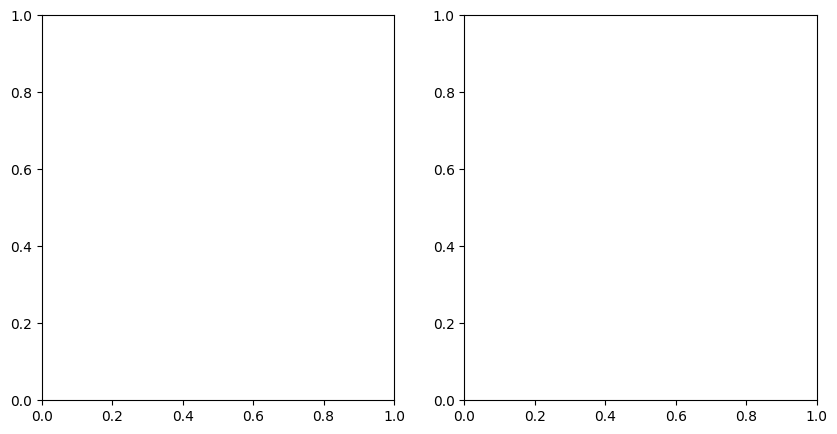

In [ ]:


def get_logbins(population, bins=50):
    hist, bins = np.histogram(population, bins=50)
    logbins = np.logspace(np.log10(bins[0]), np.log10(bins[-1]), len(bins))
    return logbins

# poiss_pop_1 = emission_prob(1, L_source.value)
# poiss_pop_0 = emission_prob(0, L_source.value)
fig, ax = plt.subplots(1, 2, figsize=(10,5))

ax[0].hist(L_source.value, bins=get_logbins(L_source.value, bins=50))

for i in range(3):
    poiss_pop = emission_prob(i, L_source.value)
    ax[1].hist(poiss_pop, bins=get_logbins(poiss_pop), label=f'k={i}')





# logbins = np.logspace(-4, 1, 50)
# plt.hist(poiss_pop_1, bins=logbins, label='k=1')
for ax_i in ax:
    ax_i.set_xscale('log')
    ax_i.set_yscale('log')
    ax_i.legend()
ax[0].set_title('Expected neutrinos from source')
ax[0].set_xlabel(r'$n_{j,SN}$')
ax[1].set_xlabel(r'$Poiss(k, n_{kj})$')
ax[1].set_title('Poission emission probability')
plt.show()


Let's study how the spatial probability behaves in our maps.

In [ ]:
ra, dec = sim_values['sources']['ra'], sim_values['sources']['dec'] 
sample_alerts = np.random.choice(range(len(alerts)), 10)
#     'skymap': alerts[test_alert_index][0],
#     'moc': alerts[test_alert_index][1]
# }
spatial_dist = {}
for alert_i in sample_alerts:
    ra_zoom, dec_zoom = get_max_ra_dec_from_map(alerts[alert_i]['moc'])
    area_90 = get_map_area(alerts[alert_i], p=0.9)

    # get_moc_map_metadata(map_data['skymap'])

    selection_zoom = get_selection_zoom(ra, dec, ra_zoom, dec_zoom, area_90=area_90)

    spatial_dist[str(alert_i)] = {}
    for key, p in zip(['50%', '90%', '99%'], [0.5, 0.9, 0.99]):
        bool_array = is_source_in_contour_area(alerts[alert_i]['skymap'], ra[selection_zoom], dec[selection_zoom], p=p, return_bool=True)
        ra_p, dec_p = ra[selection_zoom][bool_array], dec[selection_zoom][bool_array]
        spatial_dist[str(alert_i)][key] = evaluate_map(alerts[alert_i]['skymap'], ra_p, dec_p)

# ra_50, dec_50 = is_source_in_contour_area(alerts[test_alert_index]['skymap'], ra[selection_zoom], dec[selection_zoom], p=0.5)
# spatial_50 = evaluate_map(alerts[test_alert_index]['skymap'], ra_50, dec_50)

Area 50%:  0.7474959027661954 deg2
Area 90%:  2.517880935633501 deg2


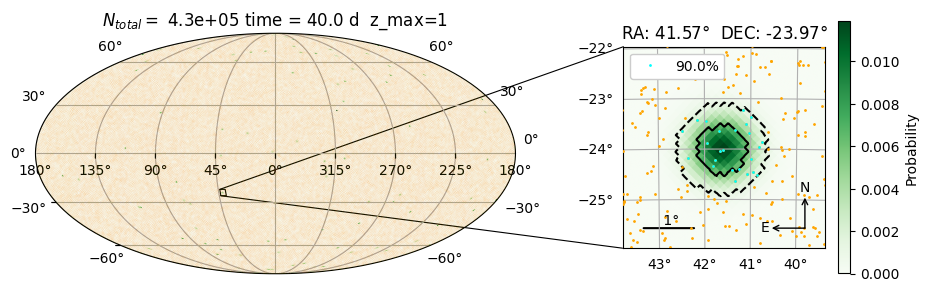

In [ ]:
alert = plot_population(population, alerts, r=2, p=0.9, plot_specific_alert=alert_i) 

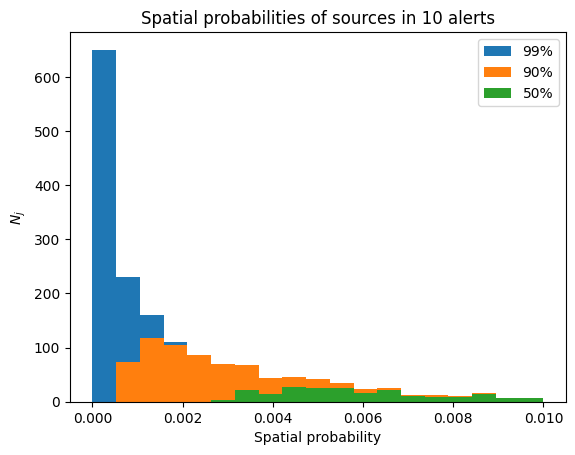

In [ ]:
total = {
    '99%': list(),
    '90%': list(),
    '50%': list(),
}
for alert in spatial_dist.keys():
    for key in spatial_dist[alert].keys():
        total[key].extend(spatial_dist[alert][key])
bins=np.linspace(0, 0.01, 20)
# key_list = list(spatial_dist.keys())
# key_list.reverse()
for key in total.keys():
    plt.hist(total[key], bins=bins, label=key)
plt.legend()
plt.title('Spatial probabilities of sources in 10 alerts')
plt.xlabel('Spatial probability')
plt.ylabel(r'$N_j$')
plt.show()

(<matplotlib.image.AxesImage at 0x12f15a7e0>, <Mollview: >)

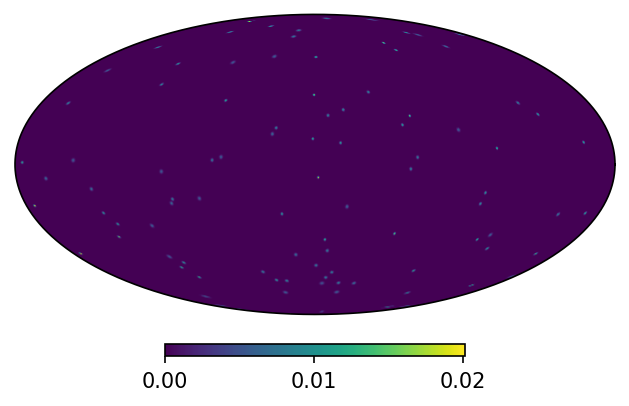

In [ ]:
tot = copy.deepcopy(alerts[0]['moc'])
for alert in alerts[1:]:
    tot += alert['moc']
tot.plot()


Channel = gfu-bronze

Check: integrated pdf for dec = -45:  0.9622811057923875
Check: integrated pdf for dec = -30:  0.9569813812499345
Check: integrated pdf for dec = 0:  0.968069952939237
Check: integrated pdf for dec = 30:  0.9097714686526037
Check: integrated pdf for dec = 45:  0.9097714686526037
Channel = gfu-gold

Check: integrated pdf for dec = -45:  0.9659646770273401
Check: integrated pdf for dec = -30:  0.9568968044891119
Check: integrated pdf for dec = 0:  0.9774691110852521
Check: integrated pdf for dec = 30:  0.9027143776313511
Check: integrated pdf for dec = 45:  0.9027143776313511
Channel = hese-bronze

Check: integrated pdf for dec = -45:  0.7664356651469237
Check: integrated pdf for dec = -30:  0.7500828385772428
Check: integrated pdf for dec = 0:  0.6813283144255058
Check: integrated pdf for dec = 30:  0.23771643766031983
Check: integrated pdf for dec = 45:  0.23771643766031983
Channel = hese-gold

Check: integrated pdf for dec = -45:  0.7939671630182297
Check: integr

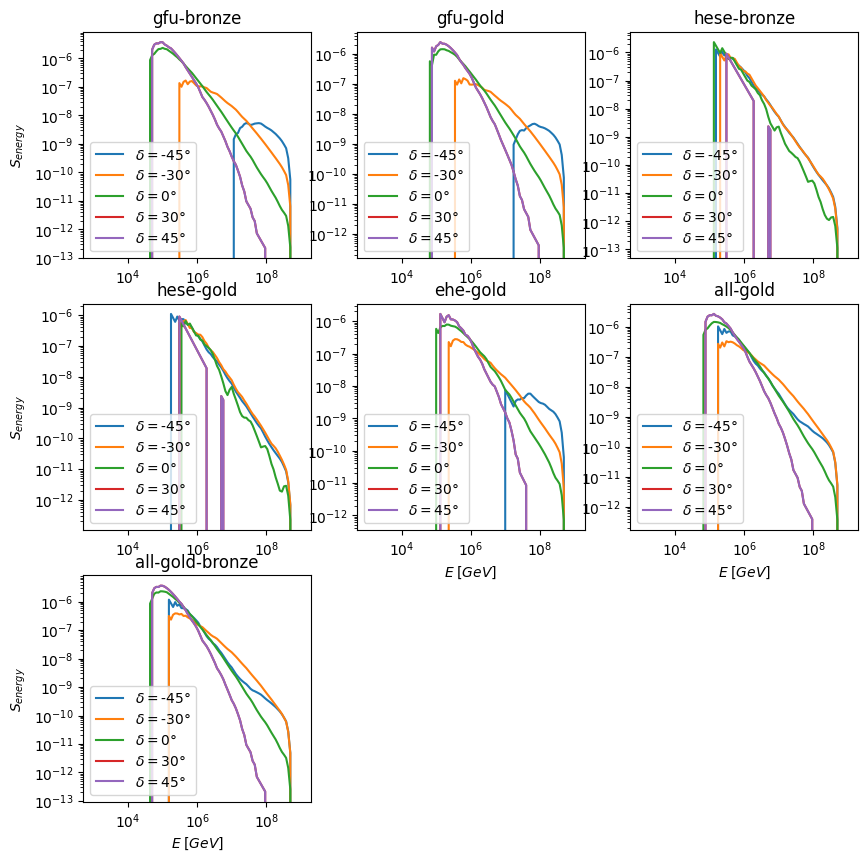

In [ ]:

E_max = 9
from params import p
E_range = np.logspace(3, E_max, 100)
fig, ax = plt.subplots(3, 3, figsize=(10, 10))

ax_list = [ax[i][j] for i in range(len(ax)) for j in range(len(ax[i]))] 
for ax_i, channel in zip(ax_list, list(p['Eff_area'].keys())[1:]):
    print(f'Channel = {channel}\n')
    for dec in [-45, -30, 0, 30, 45]:
        energy_pdf = []
        for E_i in E_range:
            energy_pdf.extend(signal_energy_pdf(E_i, delta_j=dec, channel=channel, E_max=E_max))
        ax_i.plot(E_range, energy_pdf, label=r'$\delta=$'+f'{dec}'+r'$\degree$')
        ax_i.set_title(channel)
        ax_i.loglog()
        ax_i.legend()
        

        #check
        print(f'Check: integrated pdf for dec = {dec}: ', scipy.integrate.trapezoid(energy_pdf, E_range))
    # ax[0][0].set_ylabel(r'$S_{energy}$')
    
    ax[2][1].set_visible(False)
    ax[2][2].set_visible(False)
    ax[2][0].set_xlabel(r'$E\;[GeV]$')
    ax[1][1].set_xlabel(r'$E\;[GeV]$')
    ax[1][2].set_xlabel(r'$E\;[GeV]$')
    for i in range(len(ax)):
        ax[i][0].set_ylabel(r'$S_{energy}$')

plt.savefig('/Users/cristozilleruelo/Desktop/s_energy_pdf.jpg', bbox_inches='tight')
plt.show()

In [ ]:
def get_rubicube(alert_i, alerts, sim_values, E_i):
    ra = sim_values['sources']['ra']
    dec = sim_values['sources']['dec']

    ra_zoom, dec_zoom = get_max_ra_dec_from_map(alerts[alert_i]['moc'])
    area_90 = get_map_area(alerts[alert_i], p=0.9)

    # get_moc_map_metadata(map_data['skymap'])

    selection_zoom = get_selection_zoom(ra, dec, ra_zoom, dec_zoom, area_90=area_90)

    spatial_dist = {}
    n_jk = {}
    poiss_dist = {}
    temporal_distribution = {}
    signal_distribution = {}

    rubicube = {}


    for key, p in zip(['50%', '90%', '99%'], [0.5, 0.9, 0.99]):
        bool_array = is_source_in_contour_area(alerts[alert_i]['skymap'], ra[selection_zoom], dec[selection_zoom], p=p, return_bool=True)
        ra_p, dec_p  = ra[selection_zoom][bool_array], dec[selection_zoom][bool_array]
        z_p = sim_values['sources']['z'][selection_zoom][bool_array]

        spatial_dist[key] = evaluate_map(alerts[alert_i]['skymap'], ra_p, dec_p)
        n_jk[key] = get_njk(z_p, dec_p, sim_values).value
        # poiss_dist[key] = emission_prob(1, n_jk[key])
        temporal_distribution[key] = 1/40 * np.ones(len(dec_p))
        # print((E_i * np.ones(len(dec_p))).shape)
        # print(dec_p.shape)
        signal_distribution[key] = signal_energy_pdf(E_i * np.ones(len(dec_p)), delta_j=dec_p)
        # print(len(n_jk[key]))
        # print(len(spatial_dist[key]))
        # print(len(temporal_distribution[key]))
        # print(len(signal_distribution[key]))

        rubicube[key] = n_jk[key] * spatial_dist[key] * temporal_distribution[key] * signal_distribution[key]
    
    probabilities = {
        'rubicube': rubicube,
        'n_jk': n_jk,
        'spatial': spatial_dist,
        'temporal': temporal_distribution,
        'signal': signal_distribution
    }
    return probabilities 
    

$$ \Phi_{z=1}^{PS} = \frac{4 \pi \Phi_\mathrm{diffuse}}
        {N_\mathrm{tot}\,d_L^2(z=1)\, \int_0^{10}
        \frac{ (1+z)^{-\gamma+2} }{d_L(z)^2}
        \frac{\frac{\mathrm{d}N}{\mathrm{d}z} V_c(z)}
        { \int_0^{z_\mathrm{max}} \frac{\mathrm{d}N}{\mathrm{d}z'}
        V_c(z') \,\mathrm{d}z'} \,\mathrm{d}z} $$

In [ ]:
alert_i = 1
probabilities = get_rubicube(alert_i, alerts, sim_values, E_i=1e5)


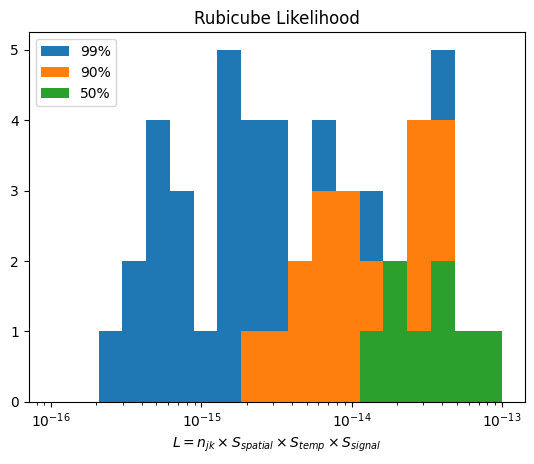

In [ ]:
logbins=np.logspace(-16,-13, 20)
for key in reversed(sorted(probabilities['rubicube'].keys())):
    plt.hist(probabilities['rubicube'][key], label=key, bins=logbins)
plt.xscale('log')
plt.xlabel(r'$L = n_{jk} \times S_{spatial}\times S_{temp} \times S_{signal}$')
plt.title('Rubicube Likelihood')
plt.legend()
plt.show()

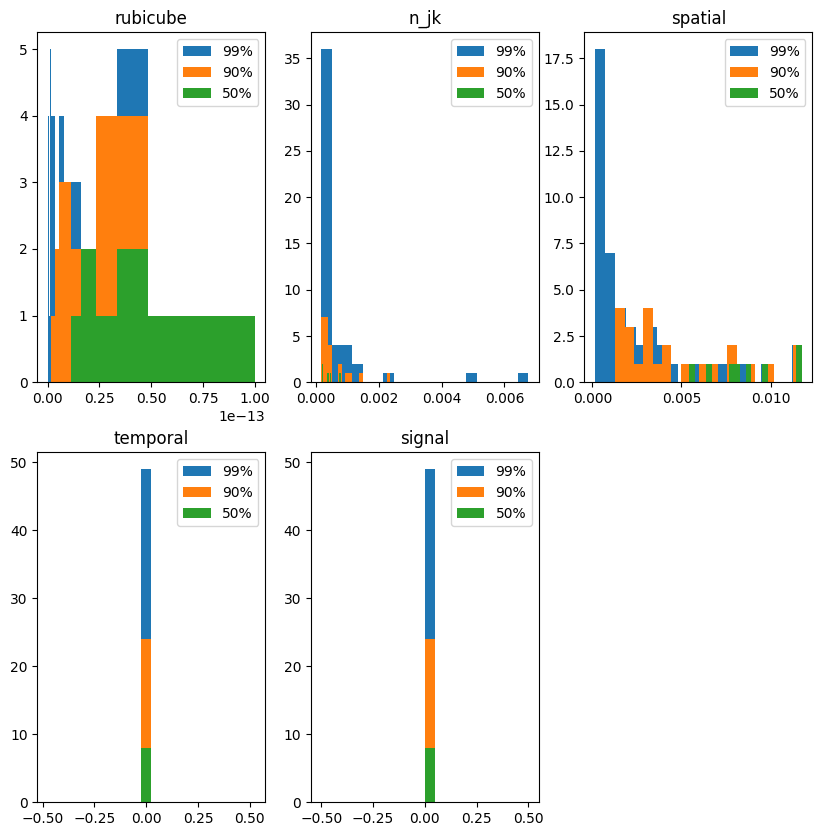

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(10,10))
ax[1][2].set_visible(False)
ax_list = []
for i in ax:
    for j in i:
        ax_list.append(j)
    
logbins = {
    'rubicube': np.logspace(-16, -13, 20),
    'n_jk': 20,
    'spatial': 20,
    'temporal':20,
    'signal': 20
}
for ax, key in zip(ax_list, probabilities.keys()):
    for p in reversed(sorted(probabilities[key].keys())):
        
        ax.hist(probabilities[key][p], label=p, bins=logbins[key])
    ax.set_title(key)
    ax.legend()



plt.show()

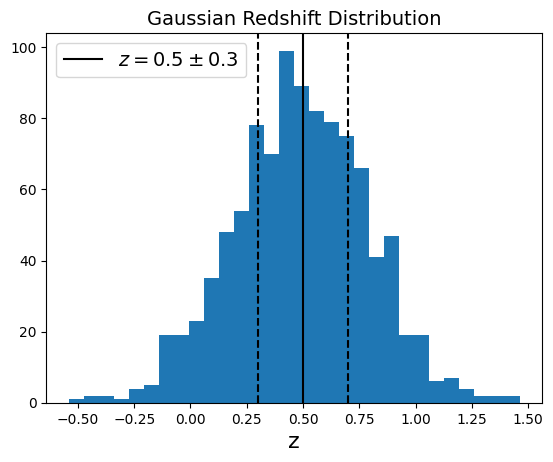

In [34]:
z = np.random.normal(0.5, 0.3, 1000) 
plt.hist(z, bins=30)
plt.axvline(0.5, c='black', label=r'$z=0.5\pm0.3$')
plt.axvline(0.5-0.2, c='black', linestyle='dashed')
plt.axvline(0.5+0.2, c='black', linestyle='dashed')
plt.xlabel('z', fontsize=16)
plt.legend(fontsize=14)
plt.title('Gaussian Redshift Distribution', fontsize=14)
plt.savefig('/Users/cristozilleruelo/Desktop/redshift_dits.png')
plt.show()

/var/folders/9g/fpz1sy1x4jbc8fm9s02wgv9c0000gn/T/ipykernel_17536/392563784.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=14)


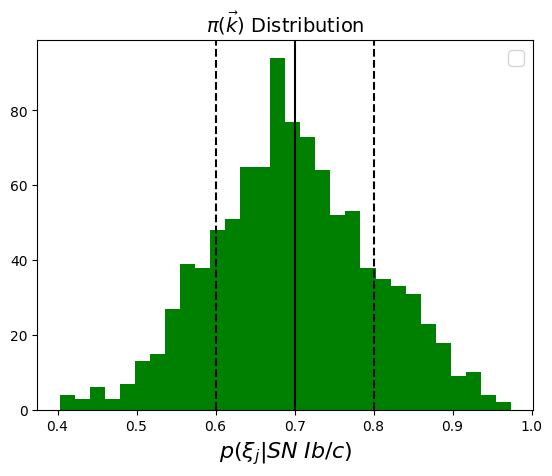

In [46]:
z = np.random.normal(0.7, 0.1, 1000) 
plt.hist(z, bins=30, color='green')
plt.axvline(0.7, c='black')#, label=r'$z=0.5\pm0.3$')
plt.axvline(0.7-0.1, c='black', linestyle='dashed')
plt.axvline(0.7+0.1, c='black', linestyle='dashed')
plt.xlabel(r'$p(\xi_j|SN \;Ib/c)$', fontsize=16)
plt.legend(fontsize=14)
plt.title(r'$\pi(\vec k)$ Distribution', fontsize=14)
plt.savefig('/Users/cristozilleruelo/Desktop/k_dits.png')
plt.show()

/var/folders/9g/fpz1sy1x4jbc8fm9s02wgv9c0000gn/T/ipykernel_17536/1500895044.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=14)


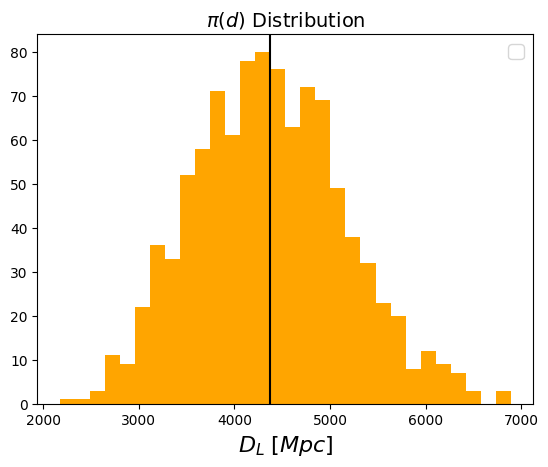

In [47]:
z = np.random.normal(0.7, 0.1, 1000) 
p=p_cosmology
cosmo = acosmo.LambdaCDM(H0=p['h0']* u.km / u.s / u.Mpc, 
                         Om0= p['omega_M'],
                        Ode0=p['omega_L'])#, Tcmb0=2.725 * u.K, 
D_L_sources = cosmo.luminosity_distance(z).to(u.Mpc).value
plt.hist(D_L_sources, bins=30, color='orange')
plt.axvline(np.mean(D_L_sources), c='black')#, label=r'$z=0.5\pm0.3$')
# plt.axvline(0.7-0.1, c='black', linestyle='dashed')
# plt.axvline(0.7+0.1, c='black', linestyle='dashed')
plt.xlabel(r'$D_L\;[Mpc]$', fontsize=16)
plt.legend(fontsize=14)
plt.title(r'$\pi(d)$ Distribution', fontsize=14)
plt.savefig('/Users/cristozilleruelo/Desktop/d_dits.png')
plt.show()